Importing the libraries

In [19]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense,  Dropout, GRU, Bidirectional, Conv1D, MaxPooling1D, Flatten
from keras.optimizers import SGD
import tensorflow as tf
import math
from sklearn.metrics import mean_squared_error

In [20]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

First, we get the data

In [21]:
dataset = pd.read_csv('GOOGL_stock_data.csv', index_col='Date', parse_dates=['Date'])

In [22]:
dataset.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,10.535383,10.863273,10.428164,10.852302,524323152,GOOGL
2006-01-04,11.068484,11.194653,10.965005,11.101896,610844544,GOOGL
2006-01-05,11.120847,11.259234,11.008641,11.251504,431899668,GOOGL
2006-01-06,11.391886,11.731745,11.301374,11.611062,709565724,GOOGL
2006-01-09,11.629763,11.804056,11.493371,11.641981,511164324,GOOGL


In [23]:
dataset.shape

(4806, 6)

In [24]:
training_set = dataset[:'2023'].iloc[:,1:2].values
test_set = dataset['2024':].iloc[:,1:2].values

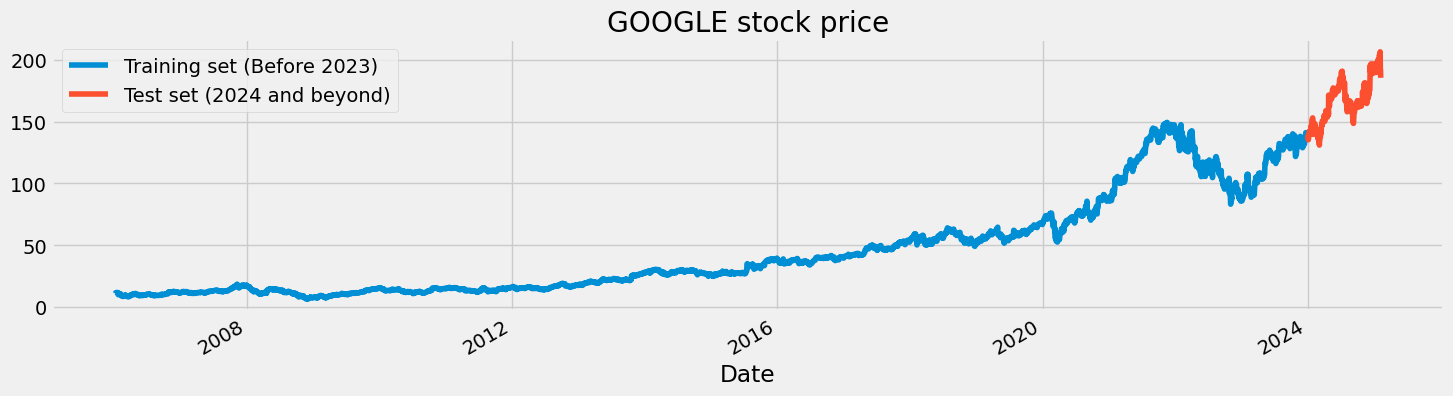

In [25]:
dataset["Close"][:'2023'].plot(figsize=(16,4),legend=True)
dataset["Close"]['2024':].plot(figsize=(16,4),legend=True)
plt.legend(['Training set (Before 2023)','Test set (2024 and beyond)'])
plt.title('GOOGLE stock price')
plt.show()

Scaling the training set

In [26]:
sc = MinMaxScaler(feature_range=(0,1))
training_set_scaled = sc.fit_transform(training_set)

we create a data structure with 60 timesteps and 1 output .So for each element of training set, we have 60 previous training set elements 

In [27]:
timestamp_structure = 60

In [28]:
X_train = []
y_train = []
for i in range(timestamp_structure,len(training_set_scaled)):
    X_train.append(training_set_scaled[i-timestamp_structure:i,0])
    y_train.append(training_set_scaled[i,0])
X_train, y_train = np.array(X_train), np.array(y_train)

Reshaping X_train for efficient modelling

In [29]:
X_train = np.reshape(X_train, (X_train.shape[0],X_train.shape[1],1))

### GRU

In [30]:
epochs = 100
batch_size = 32
loss = 'mean_squared_error'
optimizer = 'rmsprop'

In [31]:
regressorGRU = Sequential()
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, return_sequences=True, input_shape=(X_train.shape[1],1), activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(GRU(units=50, activation='tanh'))
regressorGRU.add(Dropout(0.2))
regressorGRU.add(Dense(units=1))
regressorGRU.compile(optimizer=optimizer,
                     loss=loss)
regressorGRU.fit(X_train,y_train,epochs=epochs, batch_size=batch_size)

c:\Users\Asus\Downloads\stock-price-prediction-master\venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 95ms/step - loss: 0.0109
Epoch 2/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 12s 87ms/step - loss: 0.0040
Epoch 3/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - loss: 0.0026
Epoch 4/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 126ms/step - loss: 0.0024
Epoch 5/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 99ms/step - loss: 0.0020
Epoch 6/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 127ms/step - loss: 0.0021
Epoch 7/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 91ms/step - loss: 0.0023
Epoch 8/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - loss: 0.0019
Epoch 9/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 92ms/step - loss: 0.0019
Epoch 10/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 98ms/step - loss: 0.0016
Epoch 11/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - loss: 0.0019
Epoch 12/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 140ms/step - loss: 0.0017
Epoch 13/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 113ms/step - loss: 0.0018
Epoch 14/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 13s 96ms/step - loss: 0.0017
Epoch 15/

In [32]:
dataset_total = pd.concat((dataset["High"][:'2023'],dataset["High"]['2024':]),axis=0)
inputs = dataset_total[len(dataset_total)-len(test_set) - timestamp_structure:].values
inputs = inputs.reshape(-1,1)
inputs  = sc.transform(inputs)

In [33]:
X_test = []
for i in range(timestamp_structure,len(inputs)):
    X_test.append(inputs[i-timestamp_structure:i,0])
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0],X_test.shape[1],1))
GRU_predicted_stock_price = regressorGRU.predict(X_test)
GRU_predicted_stock_price = sc.inverse_transform(GRU_predicted_stock_price)

9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step


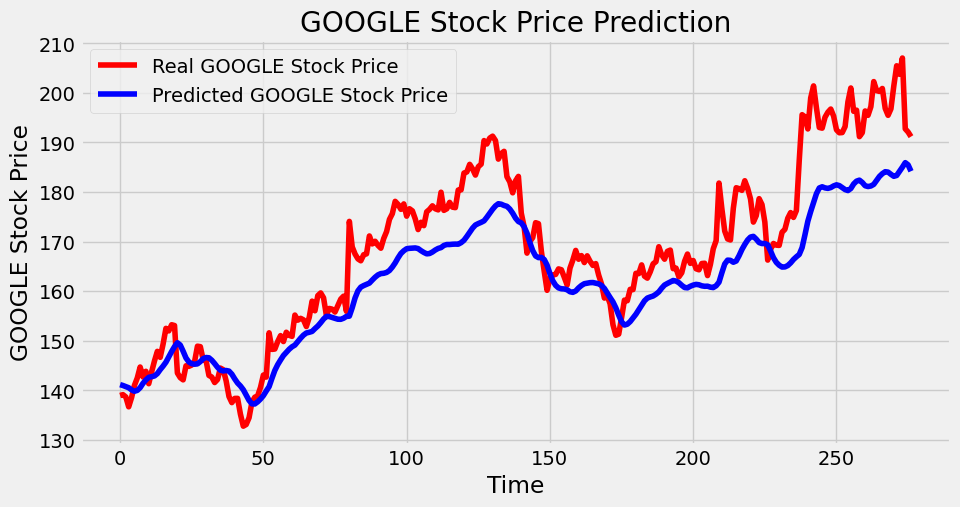

In [34]:
plt.figure(figsize=(10, 5))
plt.plot(test_set, color='red',label='Real GOOGLE Stock Price')
plt.plot(GRU_predicted_stock_price, color='blue',label='Predicted GOOGLE Stock Price')
plt.title('GOOGLE Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('GOOGLE Stock Price')
plt.legend()
plt.show()

In [35]:
rmse = math.sqrt(mean_squared_error(test_set, GRU_predicted_stock_price))
print("The root mean squared error is {}.".format(rmse))

The root mean squared error is 8.84772284653613.


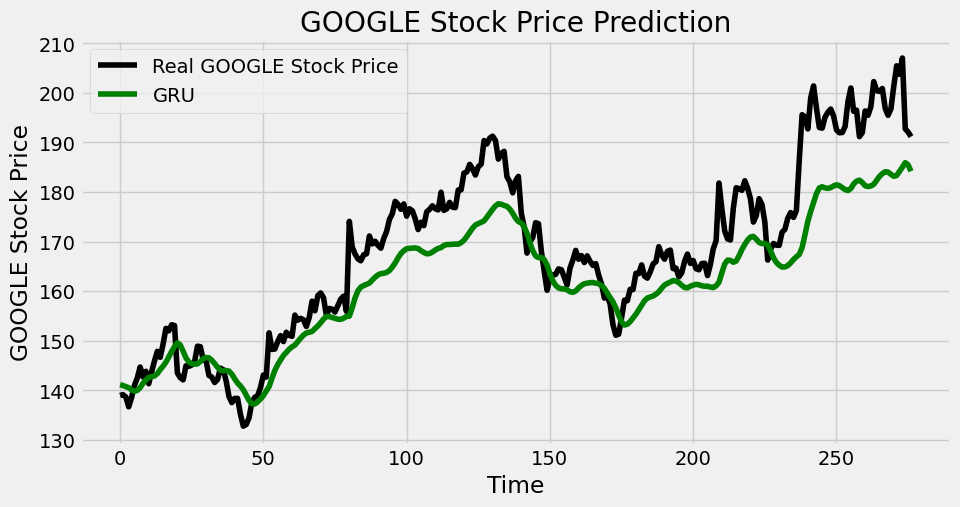

In [36]:
plt.figure(figsize=(10, 5))
plt.plot(test_set, color='black',label='Real GOOGLE Stock Price')
# plt.plot(LSTM_predicted_stock_price, color='blue',label='LSTM')
plt.plot(GRU_predicted_stock_price, color='green',label='GRU')
# plt.plot(CNN_predicted_stock_price, color='red',label='CNN')
plt.title('GOOGLE Stock Price Prediction')
plt.xlabel('Time')
plt.ylabel('GOOGLE Stock Price')
plt.legend()
plt.show()

In [1]:
# Add these imports at the top
from joblib import dump
import keras

# Save model
regressorGRU.save('gru_model.keras')

# Save scaler
dump(sc, 'scaler.joblib')

NameError: name 'regressorGRU' is not defined